# Example of the aitlas toolbox in the context of object detection 

The FAIR1M dataset contains oriented bounding boxes. This example notebook translates them into axis-oriented bounding boxes, for ease of use.

## Import the required packages

In [ ]:
from aitlas.datasets import FAIR1MDataset
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN

## Visualize images and objects with bounding boxes

Total number of patches: 1732


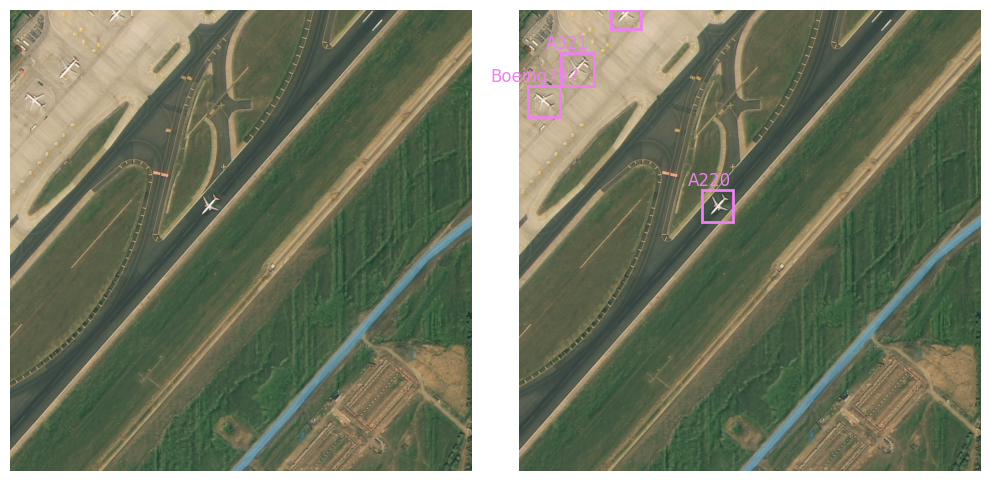

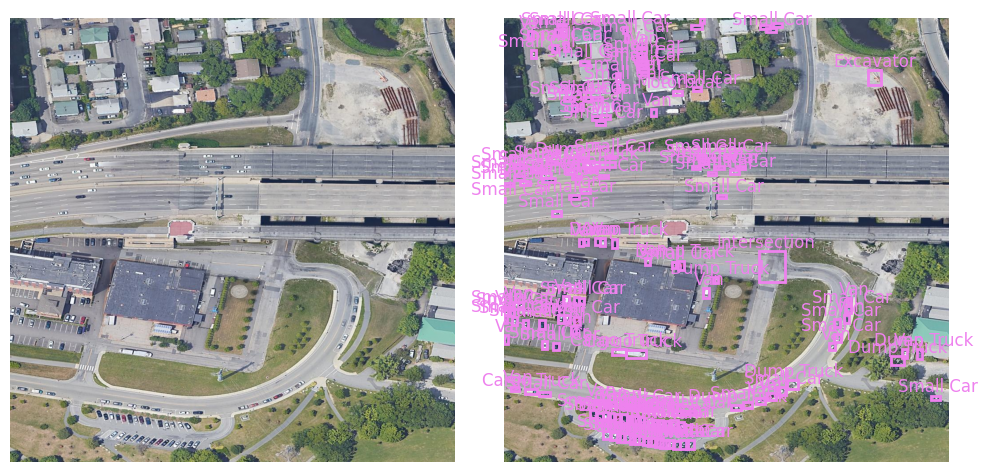

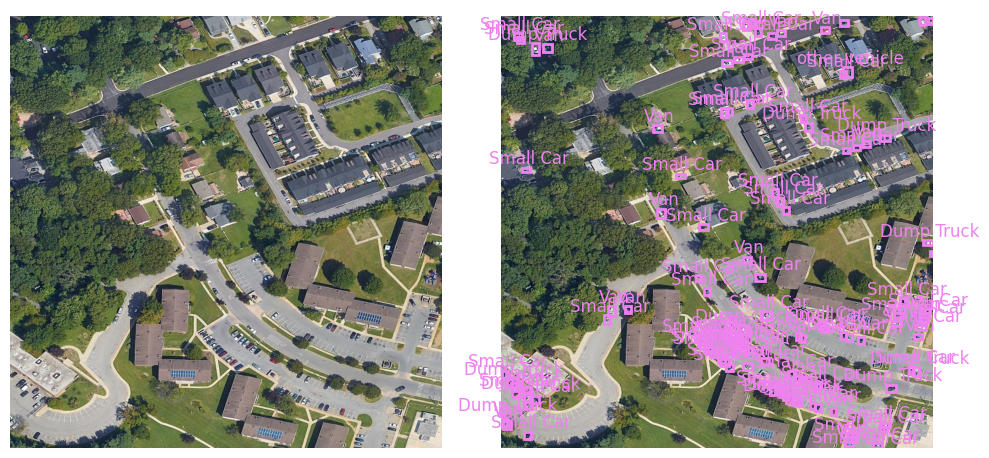

In [ ]:
dataset_config = {
    "data_dir": "./data/FAIR1M/data/images/",
    "annotation_dir": "./data/FAIR1M/data/labelXmls",
}
dataset = FAIR1MDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1005)
dataset.show_image(560)
dataset.show_image(100);

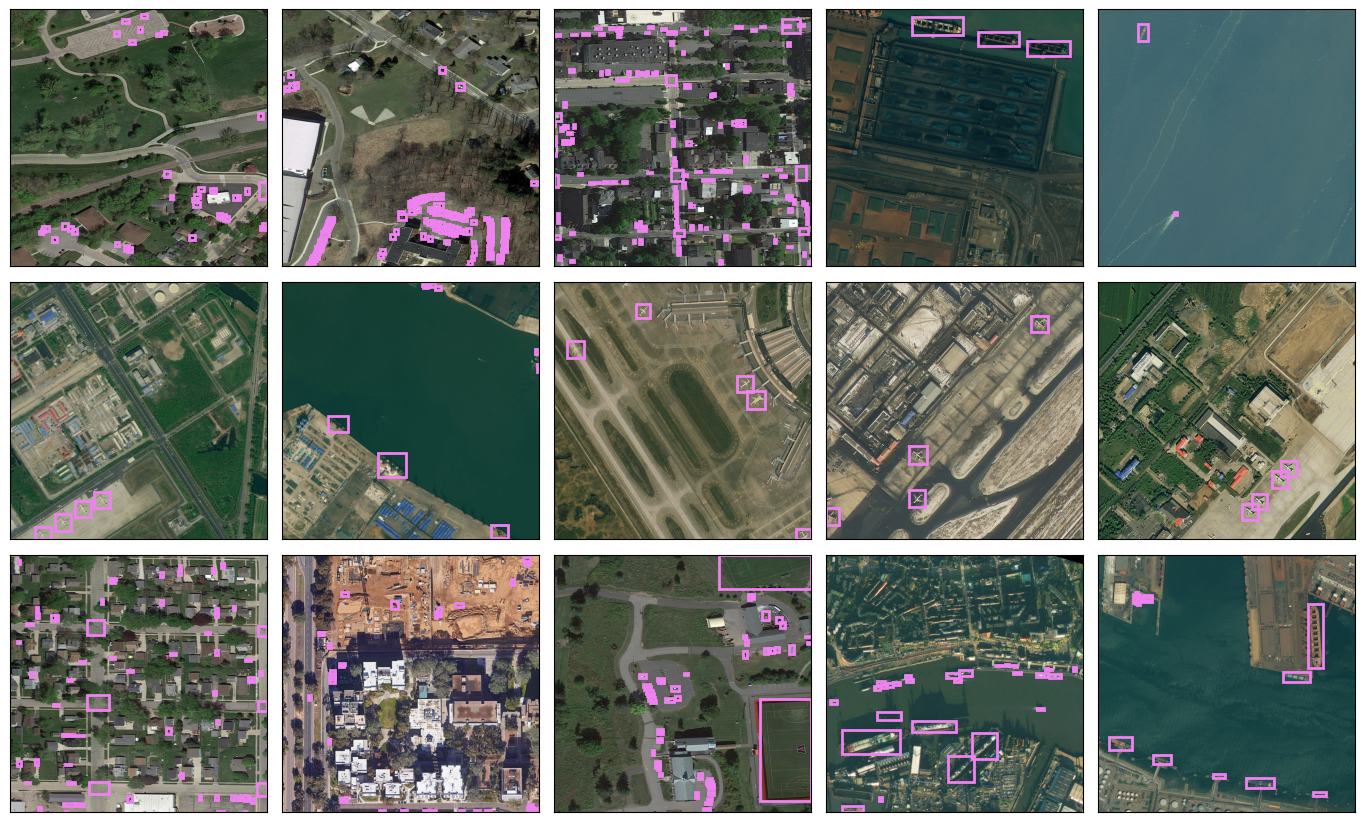

In [12]:
dataset.show_batch(15);

In [17]:
dataset.data_distribution_table()

,Label,Count
0,Boeing737,375
1,Boeing747,37
2,Boeing777,24
3,Boeing787,58
4,C919,3
5,A220,478
6,A321,269
7,A330,58
8,A350,15
9,ARJ21,18


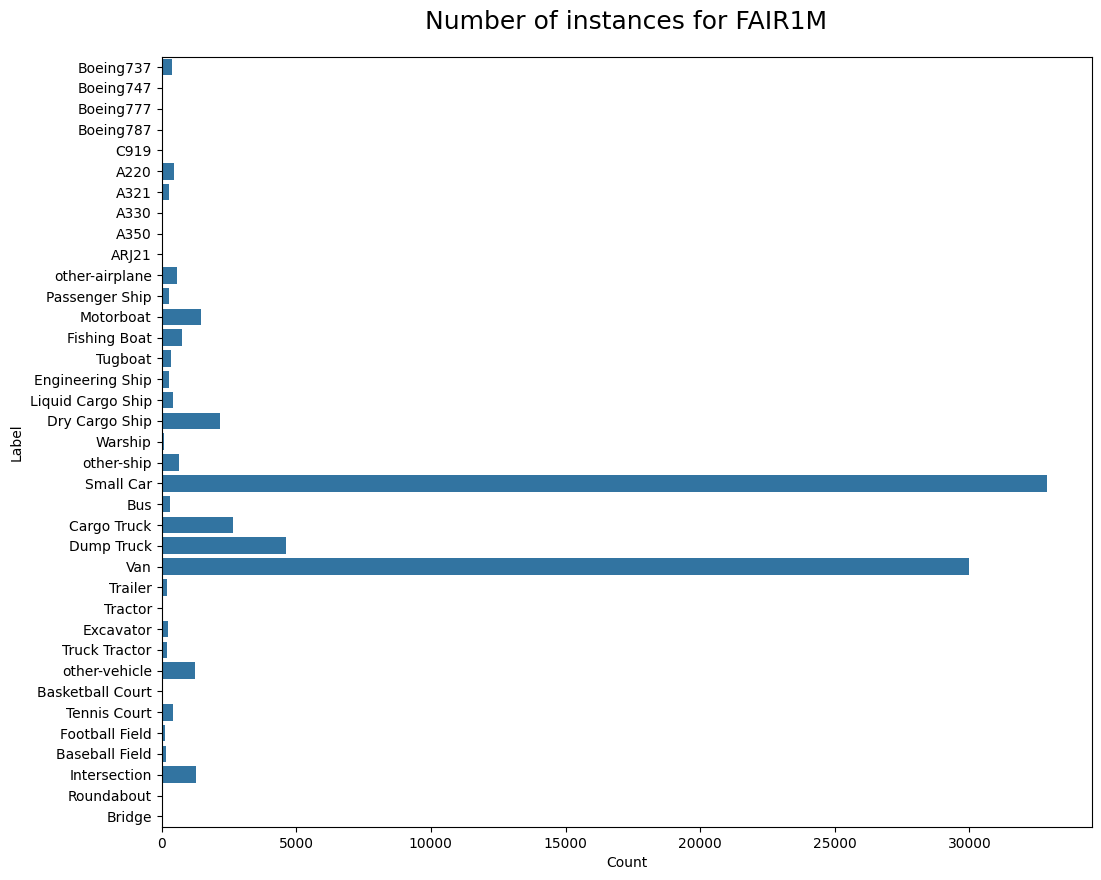

In [18]:
dataset.data_distribution_barchart();

## Load train data

In [ ]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/FAIR1M/data/images/",
    "annotation_dir": "./data/FAIR1M/data/labelXmls",
    "csv_file" : "./data/FAIR1M/train.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = FAIR1MDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 1386


## Create the model

In [ ]:
epochs = 20
model_directory = "./data/experiments/FAIR1M/"
model_config = {
    "num_classes": 38,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [15]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
)

2025-09-15 07:53:34,718 INFO Starting training.
training: 100%|██████████| 87/87 [00:57<00:00,  1.51it/s]
2025-09-15 07:54:32,454 INFO epoch: 1, time: 58, loss:  1.32423
testing on train set: 100%|██████████| 87/87 [00:35<00:00,  2.45it/s]
2025-09-15 07:55:47,473 INFO map:0.0180651992559433, map_50:0.034865882247686386, map_75:0.016824962571263313, map_small:0.016464678570628166, map_medium:0.0262566227465868, map_large:0.03532717749476433, mar_1:0.01511570904403925, mar_10:0.03601856157183647, mar_100:0.04083936661481857, mar_small:0.03390660881996155, mar_medium:0.06360767781734467, mar_large:0.0461818166077137, map_per_class:tensor(0.1537), tensor(0.), tensor(0.), tensor(0.), tensor(0.), tensor(0.0486), tensor(0.0937), tensor(0.), tensor(0.), tensor(0.), tensor(0.0912), tensor(0.), tensor(0.), tensor(0.0069), tensor(0.), tensor(0.), tensor(0.0030), tensor(0.1493), tensor(0.), tensor(0.), tensor(0.0698), tensor(0.), tensor(0.), tensor(0.), tensor(0.0521), tensor(0.), tensor(0.), tens

0.25700920304178676

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "data_dir": "./data/FAIR1M/data/images/",
    "annotation_dir": "./data/FAIR1M/data/labelXmls",
    "csv_file" : "./data/FAIR1M/val.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = FAIR1MDataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/experiments/FAIR1M/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 173


2025-09-15 08:41:31,322 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/FAIR1M/checkpoint.pth.tar
2025-09-15 08:41:31,680 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/FAIR1M/checkpoint.pth.tar at epoch 21
testing on test set: 100%|██████████| 22/22 [00:06<00:00,  3.38it/s]


[{'map': 0.166598841547966,
  'map_50': 0.24218599498271942,
  'map_75': 0.19124852120876312,
  'map_small': 0.11382947862148285,
  'map_medium': 0.3617413640022278,
  'map_large': 0.36146533489227295,
  'mar_1': 0.10057748854160309,
  'mar_10': 0.18943223357200623,
  'mar_100': 0.20051389932632446,
  'mar_small': 0.139426589012146,
  'mar_medium': 0.4065279960632324,
  'mar_large': 0.3955555558204651,
  'map_per_class': [tensor(0.4528),
   tensor(0.),
   tensor(0.),
   tensor(0.),
   tensor(0.),
   tensor(0.3226),
   tensor(0.7381),
   tensor(0.0898),
   tensor(0.),
   tensor(0.3011),
   tensor(0.),
   tensor(0.0197),
   tensor(0.1463),
   tensor(0.2830),
   tensor(0.1959),
   tensor(0.2220),
   tensor(0.3467),
   tensor(-1.),
   tensor(0.1034),
   tensor(0.1361),
   tensor(0.),
   tensor(0.0506),
   tensor(0.0340),
   tensor(0.1322),
   tensor(0.),
   tensor(0.),
   tensor(0.),
   tensor(0.),
   tensor(0.3564),
   tensor(0.5499),
   tensor(0.3211),
   tensor(0.5017),
   tensor(0.1943

## Predictions

2025-09-15 08:42:01,398 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/FAIR1M/checkpoint.pth.tar
2025-09-15 08:42:01,746 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/FAIR1M/checkpoint.pth.tar at epoch 21


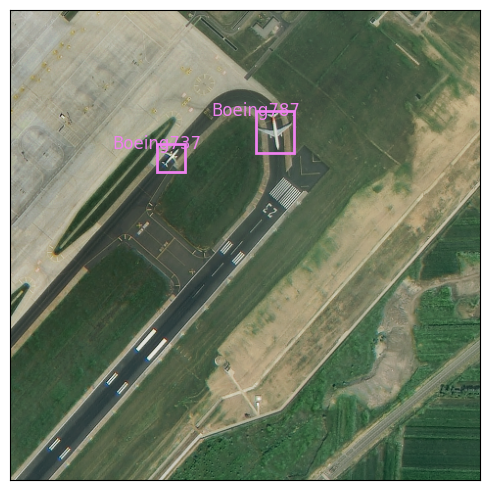

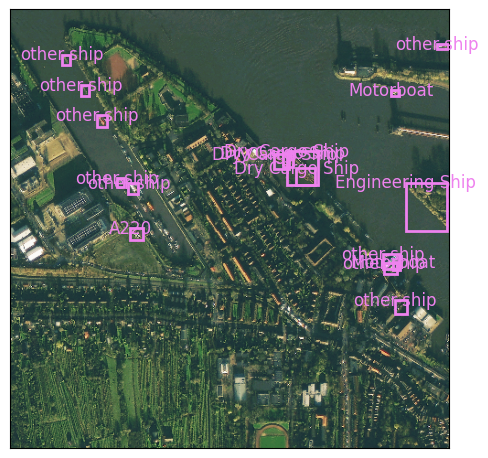

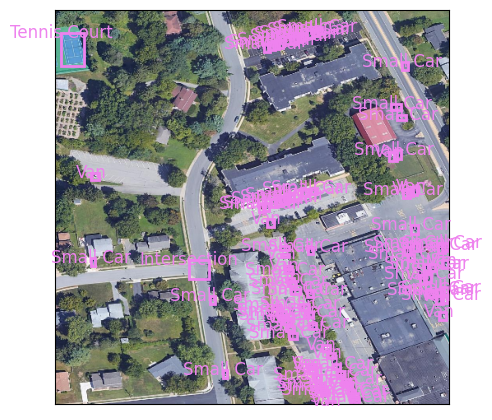

In [ ]:
model_config = {
    "num_classes": 38,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "./data/experiments/FAIR1M/checkpoint.pth.tar"
labels = ["no_data", "Boeing737", "Boeing747", "Boeing777", "Boeing787", "C919", "A220", "A321", "A330", "A350", "ARJ21",
        "other-airplane", "Passenger Ship", "Motorboat", "Fishing Boat", "Tugboat", "Engineering Ship",
        "Liquid Cargo Ship", "Dry Cargo Ship", "Warship", "other-ship", "Small Car", "Bus", "Cargo Truck",
        "Dump Truck", "Van", "Trailer", "Tractor", "Excavator", "Truck Tractor", "other-vehicle",
        "Basketball Court", "Tennis Court", "Football Field", "Baseball Field", "Intersection",
        "Roundabout", "Bridge"]
transform = Resize()
model.load_model(model_path)

image = image_loader("./data/FAIR1M/data/images/372.tif")[:,:,:3]
fig = model.detect_objects(image, labels, transform)

image = image_loader("./data/FAIR1M/data/images/438.tif")[:,:,:3]
fig = model.detect_objects(image, labels, transform)

image = image_loader("./data/FAIR1M/data/images/1078.tif")[:,:,:3]
fig = model.detect_objects(image, labels, transform)